# Results overview
This notebook loads the saved summary files in `results/` and shows every headline result of the paper. Nothing is re-fitted, so it runs in seconds. To re-run the experiments themselves, see the README.

In [1]:
import json, pandas as pd
from pathlib import Path
from IPython.display import Image, display
R = Path('..') / 'results'
E   = json.load(open(R/'study2_3/summary_study2_3.json'))
S1  = json.load(open(R/'confirmatory/summary.json'))
S4  = json.load(open(R/'study4/summary_study4.json'))
S67 = json.load(open(R/'study6_7/summary_study6_7.json'))
DS = ['wdbc','dr_debrecen','cleveland','ilpd','parkinsons','mammographic','ctg','cdc_diabetes']

## 1. Primary comparison: E3 − S* per dataset (25 folds each)

In [2]:
rows=[]
for d in DS:
    v = E['study1_recomputed'][d] if d in E['study1_recomputed'] else E['study2'][d]
    rows.append({'dataset':d,'S* selected':v['s_star_counts'],'dAUC':v['H1']['mean_diff'],'dNDF marginal':v['H2']['mean_diff'],
                 'p (unadjusted)':v['H2']['p'],'dNDF kNN':v['H2_knn']['mean_diff']})
pd.DataFrame(rows).round(4)

,dataset,S* selected,dAUC,dNDF marginal,p (unadjusted),dNDF kNN
0,wdbc,"{'lr': 19, 'svm': 4, 'rf': 2}",0.0017,-0.0556,0.1585,-0.0166
1,dr_debrecen,{'lr': 25},-0.0035,-0.6929,0.0010,-0.0902
2,cleveland,"{'lr': 21, 'rf': 3, 'svm': 1}",0.0029,-0.0758,0.4049,-0.0417
3,ilpd,"{'lr': 23, 'rf': 2}",-0.0162,-0.3388,0.0062,-0.0833
4,parkinsons,"{'xgb': 12, 'rf': 7, 'knn': 5, 'lr': 1}",0.0147,-0.1214,0.2281,-0.0658
5,mammographic,{'lr': 25},-0.0109,-0.0405,0.3095,-0.0618
6,ctg,{'rf': 25},0.0006,0.0371,0.4152,-0.0085
7,cdc_diabetes,{'lr': 25},-0.0043,-0.2246,0.0110,-0.1782


## 2. Pooled (random effects) over 8 datasets

In [3]:
pd.DataFrame({k:E['meta'][k] for k in ['H1_8','H2_8','H2_knn_8']}).T[['pooled','ci_low','ci_high','p','I2']].round(4)

,pooled,ci_low,ci_high,p,I2
H1_8,-0.0007,-0.0035,0.0021,0.6471,0.1419
H2_8,-0.1247,-0.2167,-0.0327,0.0079,0.7431
H2_knn_8,-0.0257,-0.0551,0.0038,0.0875,0.0000


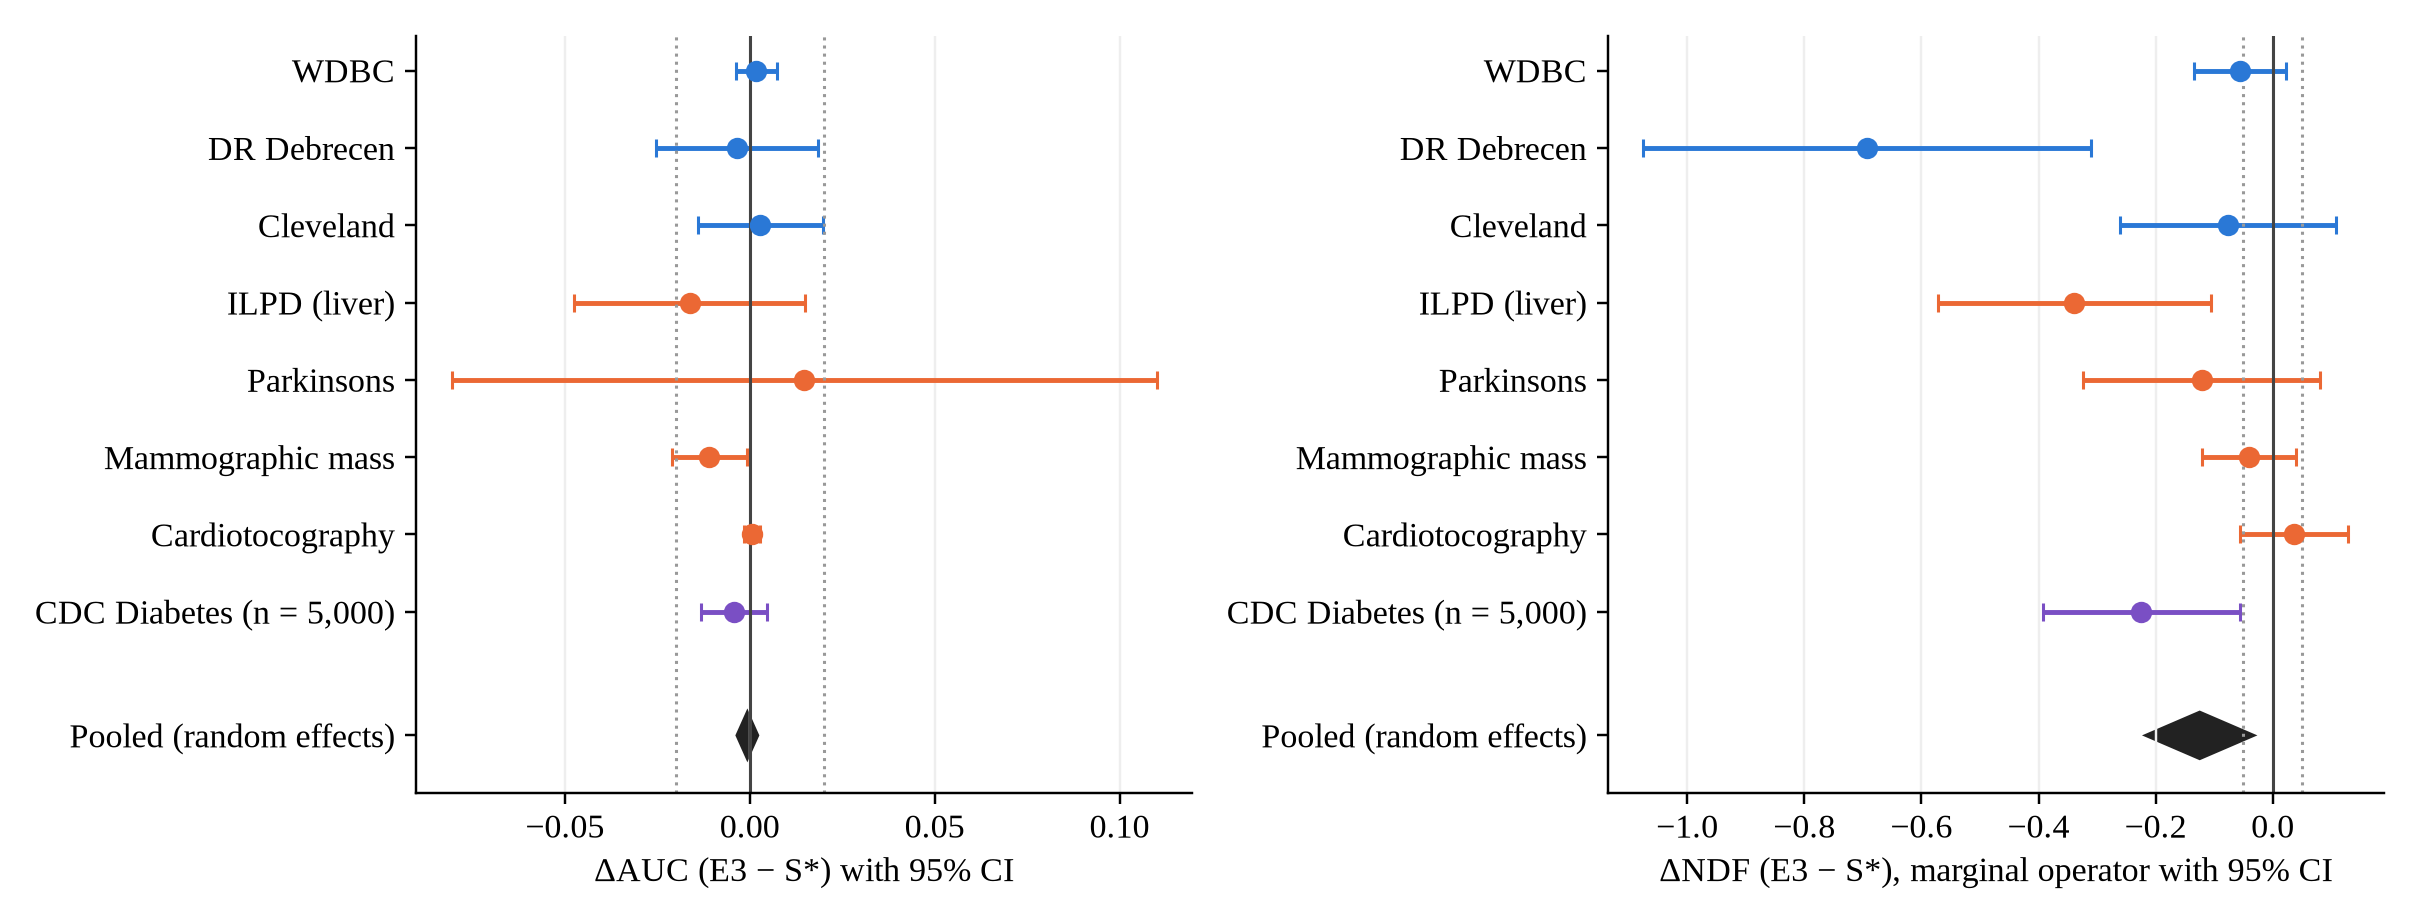

In [4]:
display(Image(filename=str(R/'study2_3/figures/fig_forest_7_datasets.png'), width=900))

## 3. Robustness: held-out repetitions (Study 6), KernelSHAP (Study 4), tuned models (Study 7)

In [5]:
S6, S7 = S67['study6'], S67['study7']
pd.DataFrame({'held-out reps (S6)': S6['pooled']['d_feat'], 'KernelSHAP (S4)': S4['pooled']['b_ndf'],
              'tuned (S7)': S7['pooled']['tuned_H2'], 'untuned same folds (S7)': S7['pooled']['untuned_H2'],
              'tuned dAUC (S7)': S7['pooled']['tuned_H1']}).T[['pooled','ci_low','ci_high','p']].round(4)

,pooled,ci_low,ci_high,p
held-out reps (S6),-0.1267,-0.2218,-0.0315,0.0091
KernelSHAP (S4),-0.1303,-0.2283,-0.0323,0.0091
tuned (S7),-0.1182,-0.2008,-0.0356,0.0050
untuned same folds (S7),-0.1304,-0.2266,-0.0343,0.0079
tuned dAUC (S7),-0.0001,-0.0012,0.0009,0.7792


## 4. Simulation (Study 3)

,truth,rho,op,mean_dndf,ci_low,ci_high
0,L,0.0,knn,-0.014,-0.140,0.112
1,L,0.0,marg,-0.045,-0.166,0.076
2,L,0.5,knn,-0.018,-0.087,0.051
3,L,0.5,marg,-0.087,-0.159,-0.015
4,L,0.9,knn,-0.036,-0.129,0.058
5,L,0.9,marg,-0.222,-0.330,-0.114
6,N,0.0,knn,0.050,-0.082,0.182
7,N,0.0,marg,0.027,-0.104,0.158
8,N,0.5,knn,0.058,-0.030,0.145
9,N,0.5,marg,-0.023,-0.111,0.065


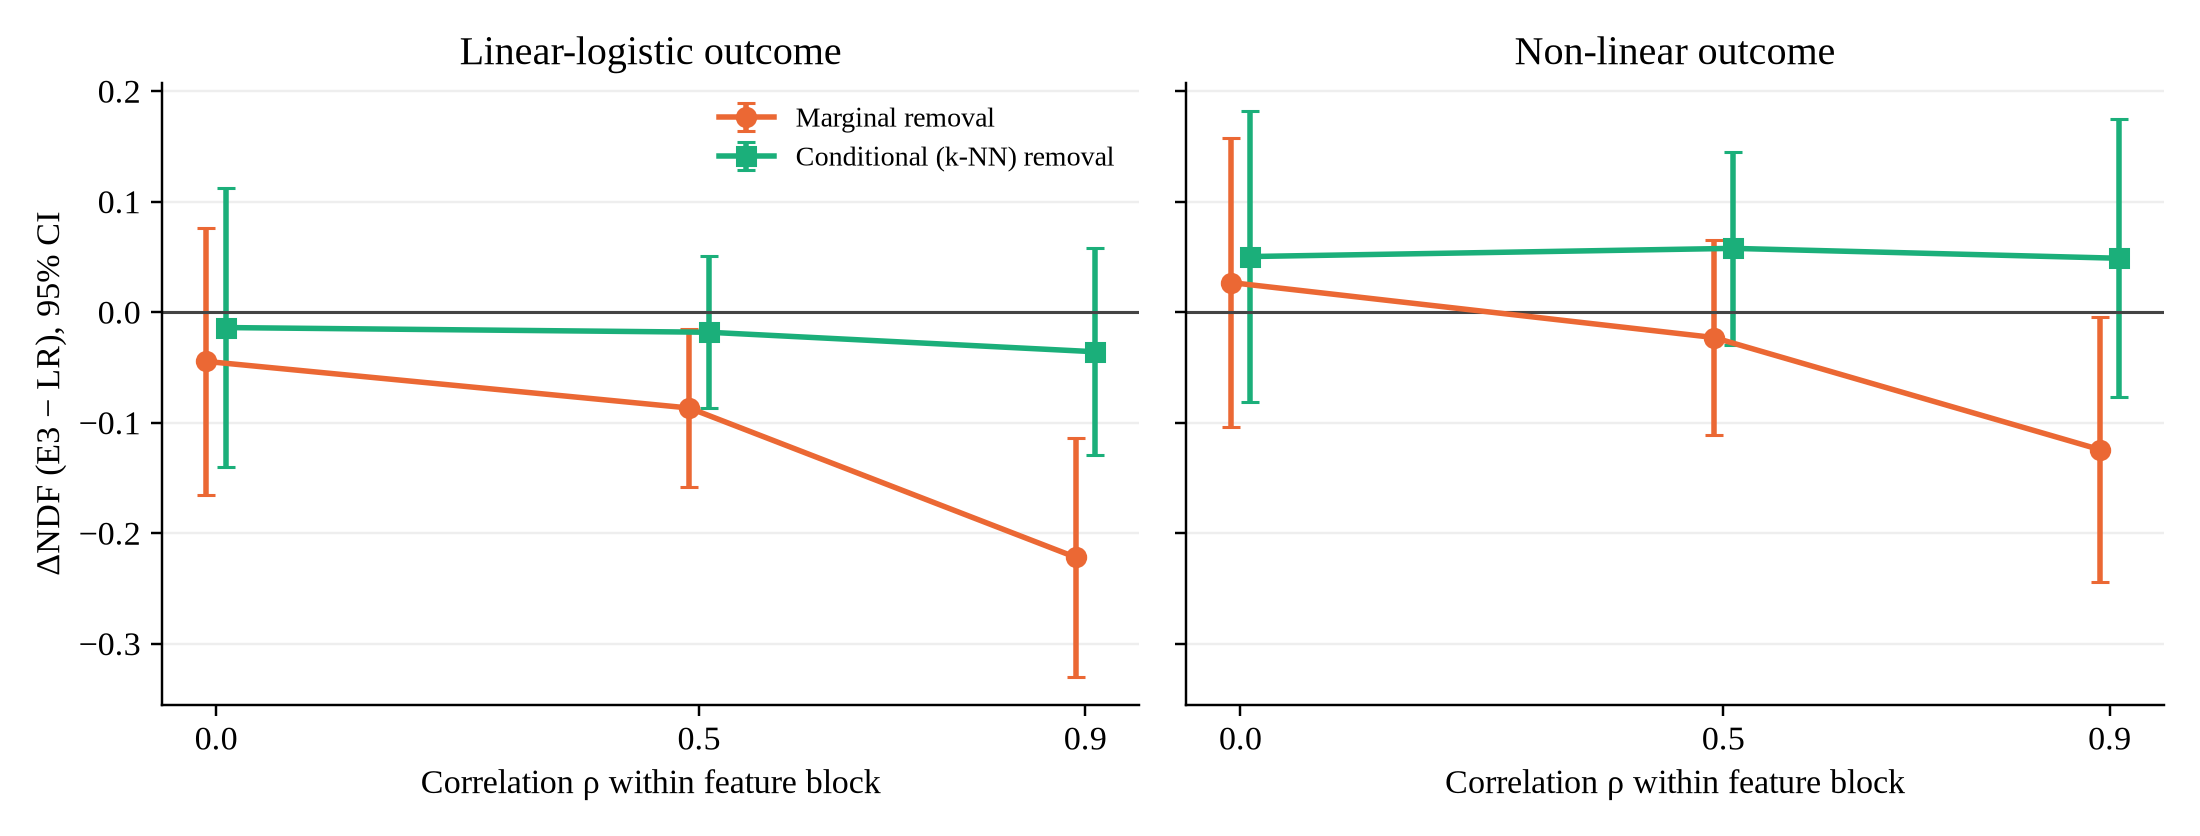

In [6]:
display(pd.DataFrame(E['study3_summary'])[['truth','rho','op','mean_dndf','ci_low','ci_high']].round(3))
display(Image(filename=str(R/'study2_3/figures/fig_simulation.png'), width=800))

## 5. Correlation-group remedy: exploratory (Study 4) and pre-specified held-out test (Study 6)

In [7]:
pd.DataFrame([{'dataset':d,'S4 reduction':S4['contrast'][d]['c_minus_a']['mean_diff'],
  'S6 feature dNDF':S6['per_dataset'][d]['d_feat']['mean_diff'],'S6 group dNDF':S6['per_dataset'][d]['d_grp']['mean_diff'],
  'S6 reduction R':S6['per_dataset'][d]['R']['mean_diff'],'p(R)':S6['per_dataset'][d]['R']['p'],
  'placebo (corr - random)':S6['per_dataset'][d]['PL']['mean_diff'],'p(placebo)':S6['per_dataset'][d]['PL']['p']} for d in DS]).round(3)

,dataset,S4 reduction,S6 feature dNDF,S6 group dNDF,S6 reduction R,p(R),placebo (corr - random),p(placebo)
0,wdbc,0.077,-0.055,0.012,0.067,0.023,0.021,0.340
1,dr_debrecen,0.489,-0.760,-0.065,0.695,0.000,0.717,0.000
2,cleveland,0.002,-0.074,-0.068,0.005,0.683,0.005,0.593
3,ilpd,0.158,-0.305,-0.159,0.146,0.043,0.083,0.164
4,parkinsons,0.099,-0.111,-0.076,0.035,0.672,-0.033,0.547
5,mammographic,0.004,-0.051,-0.022,0.030,0.145,0.022,0.321
6,ctg,-0.063,0.043,-0.032,-0.075,0.000,-0.074,0.000
7,cdc_diabetes,0.005,-0.221,-0.223,-0.002,0.622,-0.001,0.901


In [8]:
print('Pooled R (H6a):', {k: round(S6['pooled']['R'][k],4) for k in ['pooled','ci_low','ci_high','p']})
print('Pooled placebo (H6b):', {k: round(S6['pooled']['PL'][k],4) for k in ['pooled','ci_low','ci_high','p']})
print('Mechanism (H6c, dNA pooled):', {k: round(S6['pooled']['d_na'][k],4) for k in ['pooled','p']})
print('Mechanism (H6c\', patient regression):', S6['mechanism_ols'])

Pooled R (H6a): {'pooled': 0.0232, 'ci_low': -0.0155, 'ci_high': 0.0618, 'p': 0.2402}
Pooled placebo (H6b): {'pooled': 0.0044, 'ci_low': -0.0278, 'ci_high': 0.0366, 'p': 0.7886}
Mechanism (H6c, dNA pooled): {'pooled': 0.0065, 'p': 0.1636}
Mechanism (H6c', patient regression): {'coef': 6.506111930360331, 'se': 0.7051334279530572, 'p': 2.78886255506361e-20, 'n': 2441}
